# Coarse dates: individuals with only coarse date information

In [1]:
import sys
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
sys.path.insert(0, '../../scripts/1-datamodels')
sys.path.insert(0, '../../scripts/3-raw_to_db/helpers')
from style import *
import datamodel_in_duckdb as D
from pydantic_to_duckdb_schema import duck_type

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
OUTPUT_PATH = Path('../../data/enriched_parquets/individual_coarse_dates.parquet')  # datamodel shape
SAVE = True  # True writes OUTPUT_PATH
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the year or the decade
COARSE_PRECISIONS = ['century', 'millennium']
UNIT = {'century': 100, 'millennium': 1000}  # years
GROUPS = ['coarse birth and death', 'coarse birth only', 'coarse death only']
FIRST_CENTURY = -8  # 8th century BC, first century in the figure
LAST_CENTURY = 20  # last century in the figure
LABEL = 'Individuals with only coarse date information'
SEED = 42

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Birth and death dates from Wikidata only. A date is **coarse** when its only Wikidata values are centuries or millennia. An individual has **only coarse date information** when no life date is precise:

- **coarse birth and death**: both dates coarse,
- **coarse birth only**: a coarse birth, no death,
- **coarse death only**: a coarse death, no birth.

An individual with one coarse date and the other precise is not counted: notebook 01 estimates the coarse date from the precise one.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH wikidata AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL) AS birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL) AS death
        FROM individual
    ),
    dates AS (
        SELECT qid,
               list_filter(birth, d -> list_contains($known, d.precision))[1] AS precise_birth,
               list_filter(birth, d -> list_contains($coarse, d.precision))[1] AS coarse_birth,
               list_filter(death, d -> list_contains($known, d.precision))[1] AS precise_death,
               list_filter(death, d -> list_contains($coarse, d.precision))[1] AS coarse_death
        FROM wikidata
    )
    SELECT qid,
           CASE WHEN precise_birth IS NOT NULL THEN 'precise' WHEN coarse_birth IS NOT NULL THEN 'coarse' ELSE 'none' END AS birth,
           CASE WHEN precise_death IS NOT NULL THEN 'precise' WHEN coarse_death IS NOT NULL THEN 'coarse' ELSE 'none' END AS death,
           coarse_birth.year AS coarse_birth_year, coarse_birth.precision AS coarse_birth_precision,
           coarse_death.year AS coarse_death_year, coarse_death.precision AS coarse_death_precision,
           coalesce(precise_birth, coarse_birth, precise_death, coarse_death).year AS year,
           coalesce(precise_birth, coarse_birth, precise_death, coarse_death).precision AS precision
    FROM dates
    WHERE coalesce(precise_birth, coarse_birth, precise_death, coarse_death) IS NOT NULL
''', params={'known': KNOWN_PRECISIONS, 'coarse': COARSE_PRECISIONS}).pl()
assert people['qid'].is_unique().all()
people = people.with_columns(
    pl.when((pl.col('birth') == 'coarse') & (pl.col('death') == 'coarse')).then(pl.lit(GROUPS[0]))
    .when((pl.col('birth') == 'coarse') & (pl.col('death') == 'none')).then(pl.lit(GROUPS[1]))
    .when((pl.col('birth') == 'none') & (pl.col('death') == 'coarse')).then(pl.lit(GROUPS[2]))
    .alias('group')
)
coarse = people.filter(pl.col('group').is_not_null())
print(f'{people.height:,} individuals with a Wikidata birth or death, {coarse.height:,} of them with only coarse date information')
coarse.sample(5, seed=SEED)

7,749,373 individuals with a Wikidata birth or death, 108,030 of them with only coarse date information


qid,birth,death,coarse_birth_year,coarse_birth_precision,coarse_death_year,coarse_death_precision,year,precision,group
str,str,str,i64,str,i64,str,i64,str,str
"""Q61482126""","""coarse""","""none""",1901,"""century""",null,null,1901,"""century""","""coarse birth only"""
"""Q21583291""","""coarse""","""none""",2000,"""century""",null,null,2000,"""century""","""coarse birth only"""
"""Q95673048""","""coarse""","""coarse""",2000,"""millennium""",1950,"""century""",2000,"""millennium""","""coarse birth and death"""
"""Q51090052""","""coarse""","""none""",1950,"""century""",null,null,1950,"""century""","""coarse birth only"""
"""Q61470185""","""coarse""","""none""",1901,"""century""",null,null,1901,"""century""","""coarse birth only"""


## How many individuals

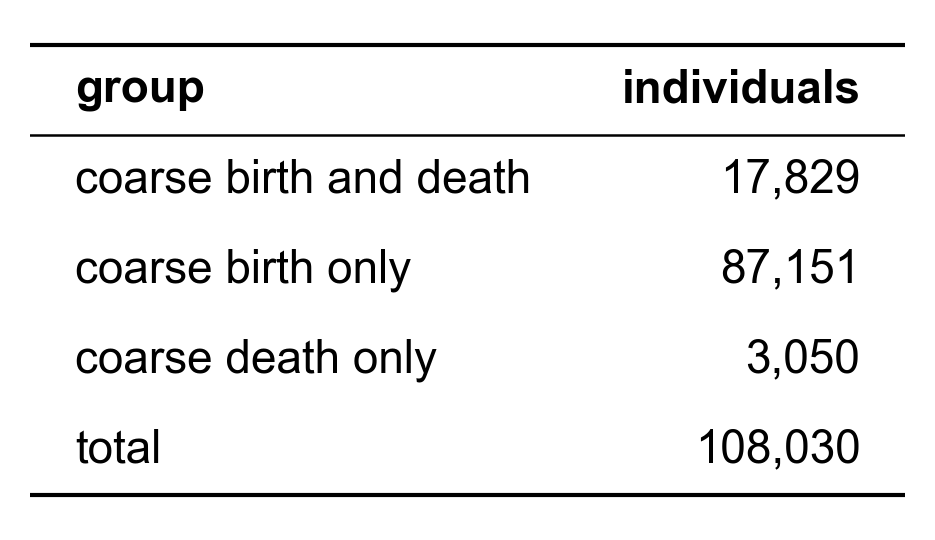

In [3]:
counts = coarse.group_by('group').len().sort(pl.col('group').replace_strict({g: i for i, g in enumerate(GROUPS)}))
show_table(pl.concat([counts, pl.DataFrame({'group': ['total'], 'len': [coarse.height]}, schema=counts.schema)])
           .select('group', pl.col('len').map_elements(lambda n: f'{n:,}', return_dtype=pl.String).alias('individuals')))

## Per century
Each individual is placed in the century of the birth, else of the death, precise or coarse. Wikidata stores a coarse century as its last year (1600 = 1501–1600), its first year (1601 = 1601–1700) or its middle (1650): the century is the one that contains the year minus one, which reads the three the same way. Individuals placed only by a millennium are left out.

In [4]:
def number(year, unit):
    """Ordinal century (or millennium) of a year, negative before the common era: 1600 → 16, 1601 → 17, −250 → −3."""
    return pl.when(year > 0).then((year - 1) // unit + 1).otherwise(-(((-year).clip(1) - 1) // unit + 1))


def ordinal(n):
    return f'{n}' + ('th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th'))


def century_label(n):
    return f'{ordinal(abs(n))} {"BC" if n < 0 else "AC"}'


placed = people.filter(pl.col('precision') != 'millennium').with_columns(number(pl.col('year'), 100).alias('century'))
print(f'{people.height:,} → {placed.height:,} after leaving out the {people.height - placed.height:,} placed by a millennium only')
per_century = (
    placed.group_by('century')
    .agg(pl.len().alias('individuals'), pl.col('group').is_not_null().sum().alias('only coarse'))
    .with_columns((100 * pl.col('only coarse') / pl.col('individuals')).alias('% only coarse'))
    .sort('century')
)
assert per_century['individuals'].sum() == placed.height
per_century.with_columns(pl.col('century').map_elements(century_label, return_dtype=pl.String), pl.col('% only coarse').round(1))

7,749,373 → 7,744,611 after leaving out the 4,762 placed by a millennium only


century,individuals,only coarse,% only coarse
str,u32,u32,f64
"""73rd BC""",1,1,100.0
"""44th BC""",1,1,100.0
"""43rd BC""",2,0,0.0
"""37th BC""",1,1,100.0
"""35th BC""",1,1,100.0
"""33rd BC""",1,0,0.0
"""32nd BC""",8,2,25.0
"""31st BC""",5,3,60.0
"""30th BC""",20,6,30.0


### Figure 1: Individuals with only coarse date information, % of the individuals of each century

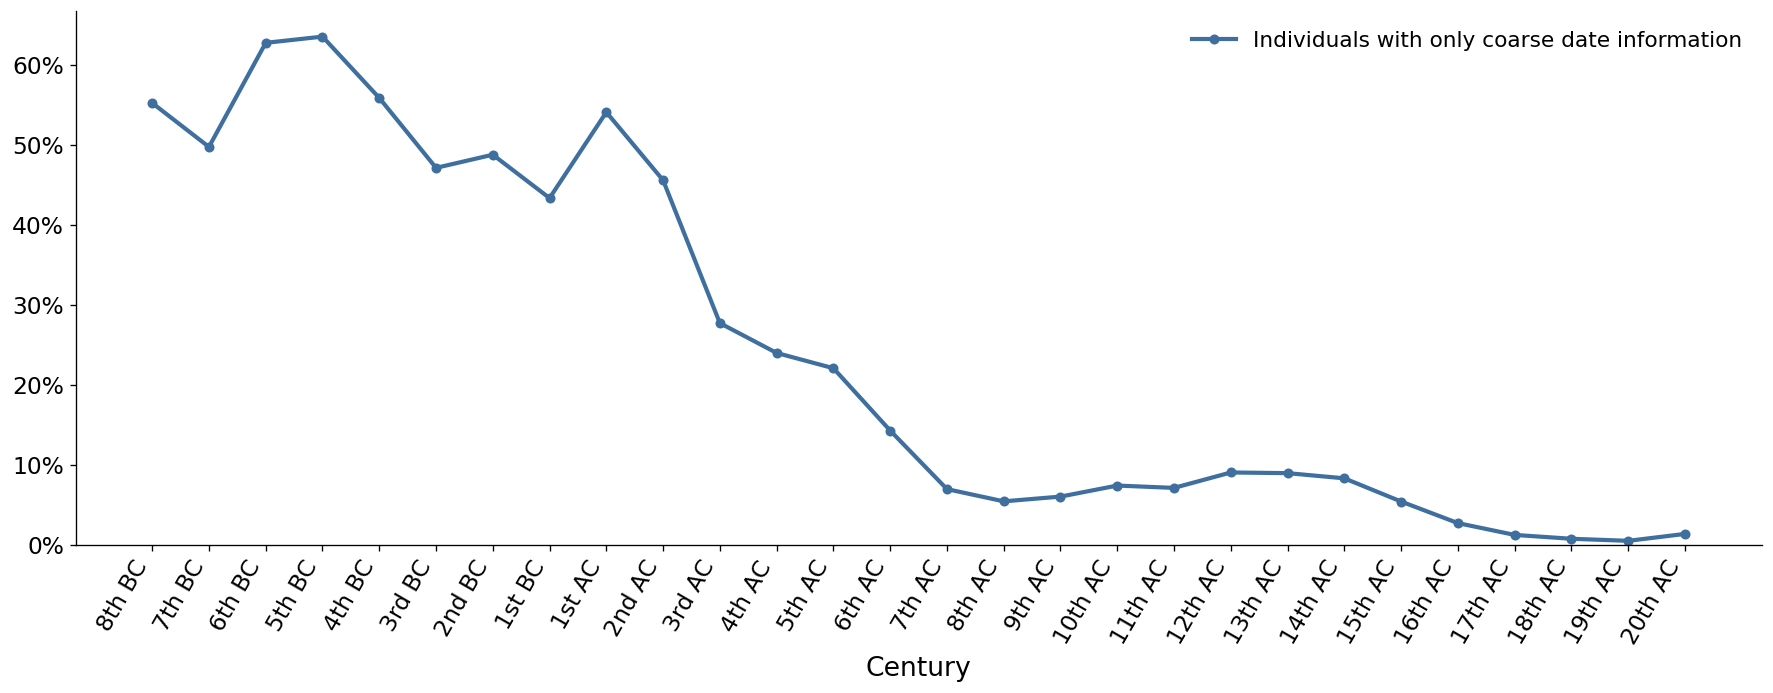

In [5]:
shown = per_century.filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
positions = list(range(shown.height))
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.plot(positions, shown['% only coarse'], color=MAIN_LINE_COLOR, linewidth=2.5, marker='o', markersize=5, label=LABEL)
ax.set_xticks(positions)
ax.set_xticklabels([century_label(c) for c in shown['century']], rotation=60, ha='right', fontsize=14)
ax.set_xlabel('Century')
ax.set_ylim(0)
ax.yaxis.set_major_formatter(PERCENT)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Save
Individuals with only coarse date information could not be imputed: they remain as they are, kept at the century level so that they are not drawn into an analysis by accident. Their birth and death keep the Wikidata precision and source, the year is left empty and `coarse_label` reads **6th AC** or **6th BC** (**2nd millennium BC** for a millennium). These categories must be removed before any use of the year.

In [6]:
def coarse_label(date):
    unit = pl.col(f'coarse_{date}_precision').replace_strict(UNIT, return_dtype=pl.Int64)
    n = number(pl.col(f'coarse_{date}_year'), unit)
    millennium = pl.when(pl.col(f'coarse_{date}_precision') == 'millennium').then(pl.lit(' millennium')).otherwise(pl.lit(''))
    era = pl.when(n < 0).then(pl.lit('BC')).otherwise(pl.lit('AC'))
    return pl.format('{}{} {}', n.abs().map_elements(ordinal, return_dtype=pl.String), millennium, era).alias(f'{date}_label')


labels = coarse.select('qid', 'coarse_birth_precision', 'coarse_death_precision', coarse_label('birth'), coarse_label('death'))
assert labels.filter(pl.col('birth_label').is_null() & pl.col('death_label').is_null()).height == 0
labels.sample(8, seed=SEED)

qid,coarse_birth_precision,coarse_death_precision,birth_label,death_label
str,str,str,str,str
"""Q61482120""","""century""",null,"""20th AC""",null
"""Q21580717""","""century""",null,"""20th AC""",null
"""Q95668233""","""century""",null,"""20th AC""",null
"""Q51089949""","""century""",null,"""20th AC""",null
"""Q61470177""","""century""","""century""","""15th AC""","""15th AC"""
"""Q45672648""","""century""",null,"""12th AC""",null
"""Q12866952""","""century""",null,"""12th AC""",null
"""Q47139554""","""century""",null,"""20th AC""",null


In [7]:
DATE_TYPE = duck_type(D.IndividualDate)
RULE = 'Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty.'


def kept_date(date):
    provenance = f"{{'raw': [], 'inputs': ['Individual.{date}_date'], 'rule': $rule, 'ai_answer': NULL, 'retrieved_on': NULL}}"
    return f"""CASE WHEN labels.{date}_label IS NOT NULL THEN CAST({{'iso': NULL, 'year': NULL, 'precision': labels.coarse_{date}_precision,
        'field_provenance': MAP {{'coarse_label': {provenance}, 'precision': {provenance}}}, 'source': 'wikidata', 'cohort': NULL,
        'coarse_label': labels.{date}_label}} AS {DATE_TYPE}) END AS {date}_date"""


con.register('labels', labels.to_arrow())
DATES = f"SELECT labels.qid, {kept_date('birth')}, {kept_date('death')} FROM labels"
con.sql(f"{DATES} LIMIT 4", params={'rule': RULE}).pl()

qid,birth_date,death_date
str,struct[7],struct[7]
"""Q100000852""","{null,null,""century"",[{""coarse_label"",{[],[""Individual.birth_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}, {""precision"",{[],[""Individual.birth_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}],""wikidata"",null,""15th AC""}","{null,null,""century"",[{""coarse_label"",{[],[""Individual.death_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}, {""precision"",{[],[""Individual.death_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}],""wikidata"",null,""15th AC""}"
"""Q1000089""","{null,null,""century"",[{""coarse_label"",{[],[""Individual.birth_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}, {""precision"",{[],[""Individual.birth_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}],""wikidata"",null,""20th AC""}",null
"""Q1000290""","{null,null,""century"",[{""coarse_label"",{[],[""Individual.birth_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}, {""precision"",{[],[""Individual.birth_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}],""wikidata"",null,""20th AC""}",null
"""Q1000386""","{null,null,""century"",[{""coarse_label"",{[],[""Individual.birth_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}, {""precision"",{[],[""Individual.birth_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}],""wikidata"",null,""2nd BC""}","{null,null,""century"",[{""coarse_label"",{[],[""Individual.death_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}, {""precision"",{[],[""Individual.death_date""],""Only coarse Wikidata dates, which could not be imputed: kept at the century level, the year left empty."",null,null}}],""wikidata"",null,""1st BC""}"


In [8]:
if SAVE:
    OUTPUT_PATH.parent.mkdir(exist_ok=True)
    con.execute(f"COPY ({DATES} ORDER BY qid) TO '{OUTPUT_PATH}' (FORMAT parquet)", {'rule': RULE})
    saved = con.sql(f"""SELECT count(*) AS individuals, count(birth_date) AS coarse_births, count(death_date) AS coarse_deaths,
                               count(*) FILTER (birth_date.year IS NOT NULL OR death_date.year IS NOT NULL) AS with_a_year
                        FROM '{OUTPUT_PATH}'""").pl()
    assert saved['individuals'][0] == coarse.height and saved['with_a_year'][0] == 0
    display(saved)

individuals,coarse_births,coarse_deaths,with_a_year
i64,i64,i64,i64
108030,104980,20879,0
